# 07 — RQ extraction (LLM), v2

One call per record (title + abstract), answers limited to fixed lists by a JSON schema, one evidence quote per field. SQ3: free one-sentence summary → LLM-proposed codebook (you review it) → reclassification.

Order: cost → run → review flags → consistency → gold set → term cross-check → charts → SQ3 → save.

In [23]:
import getpass, hashlib, json, math, os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set(style="whitegrid")
plt.rcParams.update({"font.family": "Times New Roman"})

In [ ]:
CONFIG = {
    "INPUT_PATH": "../data/04_llm_screened_corpus.json",   # same file as notebook 08
    "OUTPUT_PATH": "../data/07_rq_extraction.json",
    "REVIEW_CSV": "../data/07_eligibility_review.csv",
    "CACHE_DIR": "../data/llm_cache",
    "GOLD_PATH": "../data/07_gold_sample.json",
    "GOLD_N": 40,
    "CONSISTENCY_N": 30,
    "SEED": 42,
    "MODEL": {"name": "gpt-6-luna", "model": "gpt-6-luna", "reasoning_effort": "medium",
              "price_in": 0.10, "price_out": 0.50},
    "MAX_RETRIES": 4,
    "PERIODS": {"2016–19": (2016, 2019), "2020–22": (2020, 2022), "2023–26": (2023, 2026)},
    # Records with these camera_data_role values are left out of the charts (still saved and listed for review).
    "EXCLUDE_FROM_CHARTS": ["no_camera_data"],
}
os.makedirs(CONFIG["CACHE_DIR"], exist_ok=True)

## Fields and allowed values

In [25]:
ENUMS = {
    "sensor_platforms": ["fixed_infrastructure_camera", "drone_uav", "vehicle_mounted", "bicycle_or_rider_mounted",
                         "wearable_body_worn", "smartphone", "camera_unspecified", "other", "not_reported"],
    "camera_source": ["existing_infrastructure", "deployed_for_study", "public_dataset", "mixed", "not_reported"],
    "camera_data_role": ["main_data", "secondary_or_validation", "no_camera_data", "unclear"],
    "method_families": ["yolo", "rcnn_ssd_detr", "other_cnn", "transformer", "multi_object_tracking",
                        "segmentation", "pose_estimation", "trajectory_prediction", "classical_cv",
                        "llm_vlm", "cv_unspecified", "other", "not_reported"],
    "cv_tasks": ["detection", "tracking", "counting", "trajectory_extraction", "classification_recognition",
                 "segmentation", "pose_estimation", "behaviour_or_intention_prediction",
                 "conflict_event_detection", "anomaly_detection", "measurement_speed_distance",
                 "other", "not_reported"],
    "analysis_methods": ["descriptive_statistics", "statistical_model", "machine_learning_model",
                         "surrogate_safety_indicators", "simulation_or_game_theory", "spatial_gis_analysis",
                         "other", "not_reported"],
    "road_users": ["pedestrians", "cyclists", "scooter_micromobility", "pedestrians_and_cyclists",
                   "mixed_vulnerable_road_users", "other"],
    "privacy": ["addressed", "mentioned_only", "not_mentioned"],
}
LIST_FIELDS = ["sensor_platforms", "method_families", "cv_tasks", "analysis_methods"]
SINGLE_FIELDS = ["camera_source", "camera_data_role", "road_users", "privacy"]
FREE_FIELDS = ["method_variants", "other_detail", "observed_summary"]
EVIDENCE_KEYS = LIST_FIELDS + SINGLE_FIELDS

GUIDE = """Field definitions:
- sensor_platforms (one or more): platforms of the cameras that produced the study's own visual data.
  fixed_infrastructure_camera = CCTV, traffic, roadside, pole- or building-mounted fixed cameras.
  vehicle_mounted = car/bus cameras, dash-cams. bicycle_or_rider_mounted = on a bicycle, e-bike, scooter or helmet.
  camera_unspecified = camera or video data are used but the platform is not described.
  not_reported = the abstract mentions no visual data source at all. Ignore sensors cited only as background.
- camera_source: existing_infrastructure (footage from cameras already installed, e.g. city CCTV),
  deployed_for_study (cameras installed or flown by the authors), public_dataset (an existing dataset,
  e.g. PETS, UCSD, inD, rounD), mixed, or not_reported.
- camera_data_role: main_data = cameras, video or images are the main data analysed;
  secondary_or_validation = video/cameras only validate or complement other sensors or data;
  no_camera_data = no camera, video or image data (e.g. seismometer, BLE, GPS, questionnaires); unclear.
- method_families (one or more): computer-vision methods actually used, not only cited.
  yolo = any YOLO version. rcnn_ssd_detr = Faster/Mask R-CNN, SSD, RetinaNet, DETR. other_cnn = other CNN or
  deep-learning detectors/classifiers. classical_cv = optical flow, background subtraction, HOG, SVM, etc.
  llm_vlm = large language or vision-language / foundation models.
  cv_unspecified = computer vision or "AI-based video analytics" used but no method named.
  Do not list here models used only to analyse the extracted data (see analysis_methods).
- method_variants: exact model or tool names as written (e.g. "YOLOv8", "DeepSORT", "DataFromSky"); [] if none.
- cv_tasks (one or more): what the vision pipeline does. conflict_event_detection = identifying conflict or
  near-miss events from video.
- analysis_methods (one or more): how the extracted data are analysed after the vision step.
  statistical_model = regression, extreme-value, survival, mixed models. machine_learning_model = tree ensembles
  (XGBoost, CatBoost), SVM, neural networks trained on extracted features. surrogate_safety_indicators = TTC, PET
  or similar. simulation_or_game_theory. spatial_gis_analysis. descriptive_statistics.
- road_users: the active-mobility users the study focuses on; ignore motor vehicles that also appear.
  mixed_vulnerable_road_users = more than two kinds (e.g. pedestrians, cyclists, scooter or wheelchair users).
- observed_summary: one sentence, max 25 words, on what is observed or measured about the space or its users
  (e.g. "pedestrian-vehicle conflicts at unsignalized crosswalks measured with post-encroachment time").
- privacy: addressed = the abstract describes a privacy measure (anonymisation, blurring, edge processing for
  privacy, ethics approval); mentioned_only = privacy mentioned without a measure; not_mentioned otherwise.
- other_detail: if any field uses "other", say what it is; else "".
- evidence: for each field, a short quote (max 15 words) from the abstract supporting the answer, or "" if none."""

SYSTEM_PROMPT = ("You extract structured information from the title and abstract of papers that use cameras and "
                 "computer vision to monitor pedestrians, cyclists or scooter users. Use only what the abstract "
                 "states; use \"not_reported\" rather than guessing.\n\n" + GUIDE +
                 "\n\nRespond with a JSON object that follows the schema.")

SCHEMA = {
    "type": "object", "additionalProperties": False,
    "properties": {
        **{f: {"type": "array", "items": {"type": "string", "enum": ENUMS[f]}} for f in LIST_FIELDS},
        **{f: {"type": "string", "enum": ENUMS[f]} for f in SINGLE_FIELDS},
        "method_variants": {"type": "array", "items": {"type": "string"}},
        "other_detail": {"type": "string"},
        "observed_summary": {"type": "string"},
        "evidence": {"type": "object", "additionalProperties": False,
                     "properties": {k: {"type": "string"} for k in EVIDENCE_KEYS},
                     "required": EVIDENCE_KEYS},
    },
    "required": LIST_FIELDS + SINGLE_FIELDS + FREE_FIELDS + ["evidence"],
}
PROMPT_VERSION = hashlib.sha1((SYSTEM_PROMPT + json.dumps(SCHEMA, sort_keys=True)).encode()).hexdigest()[:10]
print("Prompt version:", PROMPT_VERSION)

Prompt version: 10b087a694


## Load corpus

In [26]:
def normalize_doi(doi):
    if not isinstance(doi, str) or not doi.strip():
        return None
    doi = re.sub(r"^(https?://)?(dx\.)?doi\.org/", "", doi.strip().lower())
    return re.sub(r"^doi:\s*", "", doi) or None


def record_key(r):
    doi = normalize_doi(r.get("doi"))
    if doi:
        return f"doi:{doi}"
    if str(r.get("scopus_id") or "").strip():
        return f"scopus:{str(r['scopus_id']).strip()}"
    return "title:" + re.sub(r"[^a-z0-9]+", " ", str(r.get("title", "")).lower()).strip()


df = pd.read_json(CONFIG["INPUT_PATH"])
df["record_key"] = [record_key(r) for r in df.to_dict("records")]
df = df.drop_duplicates("record_key").reset_index(drop=True)
df["abstract_clean"] = df["abstract"].fillna("").str.replace(r"\s*(©|Copyright).*$", "", regex=True)
df["year"] = pd.to_numeric(df["publication_date"].astype(str).str[:4], errors="coerce")
df["period"] = None
for name, (a, b) in CONFIG["PERIODS"].items():
    df.loc[df["year"].between(a, b), "period"] = name
print(f"{len(df)} records")

377 records


## Cost estimate

In [27]:
m = CONFIG["MODEL"]
tin = sum(len(SYSTEM_PROMPT) + len(t) + len(a) for t, a in zip(df["title"].fillna(""), df["abstract_clean"])) / 4
tout = len(df) * 550
print(f"~{tin/1e6:.2f}M in, ~{tout/1e6:.2f}M out -> ~US$ {tin/1e6*m['price_in'] + tout/1e6*m['price_out']:.2f} "
      f"(+ hidden reasoning tokens, consistency re-run and SQ3 passes: roughly +30%)")

~0.47M in, ~0.21M out -> ~US$ 0.15 (+ hidden reasoning tokens, consistency re-run and SQ3 passes: roughly +30%)


## LLM client and cache

In [ ]:
from openai import OpenAI
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ").strip()
client = OpenAI()
_UNSUPPORTED = set()


def call_model(system, user, schema=None, name="out"):
    base = {"model": m["model"],
            "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]}
    optional = {"temperature": 0, "reasoning_effort": m.get("reasoning_effort")}
    if schema:
        optional["response_format"] = {"type": "json_schema",
                                       "json_schema": {"name": name, "strict": True, "schema": schema}}
    while True:
        extra = {k: v for k, v in optional.items() if v is not None and k not in _UNSUPPORTED}
        if "response_format" not in extra:
            extra["response_format"] = {"type": "json_object"}   # fallback; values are checked afterwards
        try:
            r = client.chat.completions.create(**base, **extra)
            return r.choices[0].message.content, r.usage.prompt_tokens, r.usage.completion_tokens
        except Exception as e:
            msg = str(e)
            rejected = {k for k in extra if k in msg}
            if "json_schema" in msg:
                rejected.add("response_format")
            rejected -= _UNSUPPORTED
            if not rejected:
                raise
            _UNSUPPORTED.update(rejected)
            print("Not supported, retrying without:", sorted(rejected))


def parse_json(raw):
    return json.loads(re.search(r"\{.*\}", raw or "", re.DOTALL).group(0))


def fallback_value(field):
    return next((x for x in ("not_reported", "not_mentioned", "unclear", "other") if x in ENUMS[field]), ENUMS[field][-1])


def validate(raw):
    """Parse and coerce to the schema; out-of-list values become 'other'."""
    data = parse_json(raw)
    out = {}
    for f in LIST_FIELDS:
        vals = data.get(f) or []
        vals = [v if v in ENUMS[f] else "other" for v in (vals if isinstance(vals, list) else [vals])]
        out[f] = sorted(set(vals)) or [fallback_value(f)]
    for f in SINGLE_FIELDS:
        v = data.get(f)
        out[f] = v if v in ENUMS[f] else fallback_value(f)
    out["method_variants"] = [str(v) for v in (data.get("method_variants") or [])]
    out["other_detail"] = str(data.get("other_detail") or "")
    out["observed_summary"] = str(data.get("observed_summary") or "")
    ev = data.get("evidence") or {}
    out["evidence"] = {k: str(ev.get(k) or "") for k in EVIDENCE_KEYS}
    return out


def cache_path(tag):
    return os.path.join(CONFIG["CACHE_DIR"], f"07_{m['name']}__{m.get('reasoning_effort')}__{PROMPT_VERSION}{tag}.jsonl")


def run(records, tag=""):
    path, cache = cache_path(tag), {}
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            for line in f:
                row = json.loads(line); cache[row["record_key"]] = row
    todo = records[~records["record_key"].isin(cache)]
    print(f"{len(records) - len(todo)} cached, {len(todo)} to query")
    with open(path, "a", encoding="utf-8") as f:
        for _, r in tqdm(todo.iterrows(), total=len(todo)):
            user = f"Title: {r['title']}\n\nAbstract: {r['abstract_clean']}"
            for attempt in range(CONFIG["MAX_RETRIES"]):
                try:
                    raw, tin, tout = call_model(SYSTEM_PROMPT, user, SCHEMA, "extraction")
                    row = {"record_key": r["record_key"], "tokens_in": tin, "tokens_out": tout, **validate(raw)}
                    cache[r["record_key"]] = row
                    f.write(json.dumps(row, ensure_ascii=False) + "\n")
                    break
                except Exception as e:
                    if "insufficient_quota" in str(e) or "invalid_api_key" in str(e):
                        raise
                    time.sleep(2 ** attempt)
    used = [cache[k] for k in records["record_key"] if k in cache]
    print(f"answered {len(used)}/{len(records)}; ~US$ "
          f"{sum(u['tokens_in'] for u in used)/1e6*m['price_in'] + sum(u['tokens_out'] for u in used)/1e6*m['price_out']:.2f}")
    return cache

## Run

In [29]:
results = run(df)

377 cached, 0 to query


0it [00:00, ?it/s]

answered 377/377; ~US$ 0.18


## Normalize method variants

In [30]:
VARIANT_RULES = [
    (r"yol[a-z]*act", lambda mm: "YOLACT"),
    (r"\byolo\s*-?\s*v?\s*(\d+)", lambda mm: f"YOLOv{mm.group(1)}"),     # v8n, v5s ... -> v8, v5
    (r"\byolo\s*-?\s*(x|r|p)\b", lambda mm: f"YOLO{mm.group(1).upper()}"),
    (r"\byolo\b", lambda mm: "YOLO (unspecified)"),
    (r"deep\s*-?\s*sort", lambda mm: "DeepSORT"),
    (r"byte\s*-?\s*track", lambda mm: "ByteTrack"),
    (r"faster\s*-?\s*r\s*-?\s*cnn", lambda mm: "Faster R-CNN"),
    (r"mask\s*-?\s*r\s*-?\s*cnn", lambda mm: "Mask R-CNN"),
    (r"open\s*-?\s*pose", lambda mm: "OpenPose"),
    (r"data\s*from\s*sky", lambda mm: "DataFromSky"),
    (r"\bssd\b", lambda mm: "SSD"),
    (r"kalman", lambda mm: "Kalman filter"),
    (r"\bx\s*g\s*boost", lambda mm: "XGBoost"),
    (r"\bcat\s*boost", lambda mm: "CatBoost"),
]


def normalize_variant(v):
    s = v.strip().lower()
    for pattern, fn in VARIANT_RULES:
        mm = re.search(pattern, s)
        if mm:
            return fn(mm)
    return v.strip()


rows = []
for _, r in df.iterrows():
    res = results.get(r["record_key"])
    if not res:
        continue
    rows.append({"record_key": r["record_key"], "title": r["title"], "year": r["year"], "period": r["period"],
                 **{k: res[k] for k in LIST_FIELDS + SINGLE_FIELDS + ["other_detail", "observed_summary", "evidence"]},
                 "method_variants": sorted({normalize_variant(v) for v in res["method_variants"]})})
ext = pd.DataFrame(rows)
print(f"{len(ext)} records extracted")

377 records extracted


## Review flags

In [31]:
review = ext[ext["camera_data_role"] != "main_data"][["record_key", "title", "year", "camera_data_role"]].copy()
review["evidence"] = ext.loc[review.index, "evidence"].apply(lambda e: e.get("camera_data_role", ""))
review.sort_values("camera_data_role").to_csv(CONFIG["REVIEW_CSV"], index=False)
print(ext["camera_data_role"].value_counts().to_string())
print(f"\n{len(review)} records flagged for manual eligibility review -> {CONFIG['REVIEW_CSV']}")
review.sort_values("camera_data_role")[["camera_data_role", "year", "title", "evidence"]]

camera_data_role
main_data                  357
secondary_or_validation     10
unclear                      8
no_camera_data               2

20 records flagged for manual eligibility review -> ../data/09_eligibility_review.csv


,camera_data_role,year,title,evidence
65,no_camera_data,2025,Simulation of Pedestrian Behaviour in Traffic Situations Using Risk-Based A* Pathfinding,
152,no_camera_data,2024,In-Depth Analysis Based on the Phenomenon of Pedestrians Entering the Scene When Tourists Take Photos: Designing Int...,
3,secondary_or_validation,2026,Seismometer-Based Pedestrian Monitoring Using Spectral Feature Extraction and Deep Learning: A Privacy-Preserving Ap...,a camera providing ground-truth validation for all measurements
46,secondary_or_validation,2026,Roles of physical collision forces and walking characteristics on pedestrian traffic flow status,"Walking characteristics, including speed and density, were obtained through video processing technologies"
110,secondary_or_validation,2024,Assessing air quality and physical risks to E-scooter riders in urban environments through artificial intelligence a...,detect the existence of cars alongside the pollution readings
133,secondary_or_validation,2024,A LiDAR-based methodology for monitoring and collecting microscopic bicycle flow parameters on bicycle facilities,evaluated by comparing it to ground truth video
134,secondary_or_validation,2024,"Development of a hazard risk map for assessing pedestrian risk in urban flash floods: A case study in Cúcuta, Colombia",The PCSWMM ... was calibrated and validated to simulate extreme flood events.
205,secondary_or_validation,2023,Gaze Scanning at Street Crossings by Pedestrians With Homonymous Hemianopia With and Without Hemispatial Neglect,Street-crossing instances were manually annotated
226,secondary_or_validation,2022,Using Machine Learning to Estimate Pedestrian and Bicyclist Count of Intersection by Bluetooth Low Energy,validated by the benchmark count data from video footage
236,secondary_or_validation,2022,Effect of Various Speed Management Strategies on Bicycle Crashes for Urban Roads in Central Florida,adjustments were made ... based on the video detection data


In [32]:
uses_other = ext.apply(lambda r: any("other" in (r[f] if isinstance(r[f], list) else [r[f]])
                                     for f in LIST_FIELDS + SINGLE_FIELDS), axis=1)
print(f"{uses_other.sum()} records use 'other' in some field. Frequent details may deserve a category (edit ENUMS, re-run).")
ext[uses_other][["title", "other_detail"]].head(25)

55 records use 'other' in some field. Frequent details may deserve a category (edit ENUMS, re-run).


,title,other_detail
1,Bicyclists’ avoidance behavior around static and dynamic obstacles: A trajectory-based analysis using drone-recorded...,Inferential statistical comparisons are indicated by reported p-values.
23,Rethinking Urban Intersections for Sustainable Micro-Mobility: A Kinematic Comparison of E-Scooters and Bicycles at ...,The study compares bicycle users and e-scooter users; no matching combined road-user category is available.
33,AI-based Pedestrian Obstruction Analysis for Safety Assessment of Passenger Terminals,The vision pipeline measures obstruction rate using pixel-level mask occupancy in designated walking areas.
35,Research on Collision Risk Warning Methods for Vulnerable Road Users at Unsignalized Intersections,"The abstract identifies pedestrians and nonmotorized vehicles, without specifying the nonmotorized vehicle type."
36,Multimodal Intelligent Perception at an Intersection: Pedestrian and Vehicle Flow Dynamics Using a Pipeline-Based Tr...,RAG and LLM-based contextual interpretation of congestion causes and missing data.
54,A Computer Vision-Based Pedestrian Flow Management System for Footbridges and Its Applications,Monocular depth estimation.
59,A game theoretical model to examine pedestrian behaviour and safety on unsignalised slip lanes using AI-based video ...,Video-based interaction-data extraction; the specific computer-vision task is not reported.
60,Customized Signalized Intersection Control for Pedestrian Safety Enhancement through Computer Vision Technologies,Customized signalized intersection control algorithm.
64,Harnessing Semantic and Trajectory Analysis for Real-Time Pedestrian Panic Detection in Crowded Micro-Road Networks,Other CV task: density-map estimation and candidate panic-zone delineation.
71,Safety Insights from E-Scooter Rider and Bicyclist Behavior Observations in Two U.S. Cities,"Road users are e-scooter riders and bicyclists, a combination not specifically represented in the road_users options."


## Consistency: same records, second run

In [33]:
sample = df.sample(min(CONFIG["CONSISTENCY_N"], len(df)), random_state=CONFIG["SEED"])
rep = run(sample, tag="__rep")


def jaccard(a, b):
    a, b = set(a), set(b)
    return 1.0 if not a and not b else len(a & b) / len(a | b)


both = [k for k in sample["record_key"] if k in results and k in rep]
cons = {f: np.mean([jaccard(results[k][f], rep[k][f]) for k in both]) for f in LIST_FIELDS}
cons.update({f: np.mean([results[k][f] == rep[k][f] for k in both]) for f in SINGLE_FIELDS})
print(f"Run-to-run agreement on {len(both)} records (lists: mean Jaccard; single: exact match)")
pd.Series(cons).round(3)

30 cached, 0 to query


0it [00:00, ?it/s]

answered 30/30; ~US$ 0.01
Run-to-run agreement on 30 records (lists: mean Jaccard; single: exact match)


sensor_platforms    0.967
method_families     0.806
cv_tasks            0.800
analysis_methods    0.908
camera_source       0.967
camera_data_role    1.000
road_users          0.967
privacy             1.000
dtype: float64

## Gold set: agreement with manual labels

First run writes `GOLD_N` random records with empty fields to `GOLD_PATH`. Fill them from the abstract (without looking at the LLM output), using the allowed values, then re-run this cell. Fields missing in an older gold file are skipped.

In [34]:
if not os.path.exists(CONFIG["GOLD_PATH"]):
    g = ext.sample(min(CONFIG["GOLD_N"], len(ext)), random_state=CONFIG["SEED"] + 1)
    lookup = df.set_index("record_key")["abstract_clean"]
    template = [{"record_key": k, "title": t, "abstract": lookup[k],
                 **{f: [] for f in LIST_FIELDS}, **{f: "" for f in SINGLE_FIELDS}}
                for k, t in zip(g["record_key"], g["title"])]
    with open(CONFIG["GOLD_PATH"], "w", encoding="utf-8") as fh:
        json.dump({"allowed_values": ENUMS, "records": template}, fh, indent=2, ensure_ascii=False)
    print(f"Wrote {len(template)} records to label: {CONFIG['GOLD_PATH']}")
else:
    gold = pd.DataFrame(json.load(open(CONFIG["GOLD_PATH"], encoding="utf-8"))["records"])
    pred = ext.set_index("record_key")
    scores = {}
    for f in LIST_FIELDS:
        if f in gold and gold[f].apply(len).gt(0).any():
            g = gold[gold[f].apply(len) > 0]
            scores[f] = np.mean([jaccard(r[f], pred.loc[r["record_key"], f]) for _, r in g.iterrows()])
    for f in SINGLE_FIELDS:
        if f in gold and (gold[f].astype(str).str.len() > 0).any():
            g = gold[gold[f].astype(str).str.len() > 0]
            scores[f] = np.mean([r[f] == pred.loc[r["record_key"], f] for _, r in g.iterrows()])
    print(f"Agreement with manual labels (lists: Jaccard; single: exact), {len(gold)} records in file")
    display(pd.Series(scores).round(3))

Agreement with manual labels (lists: Jaccard; single: exact), 40 records in file


sensor_platforms    0.900
method_families     0.673
cv_tasks            0.762
analysis_methods    0.733
camera_source       0.525
camera_data_role    0.900
road_users          0.975
privacy             1.000
dtype: float64

## Cross-check with notebook 08 terms

In [35]:
text = (df["title"].fillna("") + " " + df["abstract_clean"]).str.lower()
term = pd.DataFrame({"record_key": df["record_key"],
                     "t_yolo": text.str.contains(r"\byolo"),
                     "t_drone": text.str.contains(r"drone|\buavs?\b|unmanned aerial")})
chk = ext.merge(term, on="record_key")
chk["l_yolo"] = chk["method_families"].apply(lambda v: "yolo" in v)
chk["l_drone"] = chk["sensor_platforms"].apply(lambda v: "drone_uav" in v)
for name in ("yolo", "drone"):
    dis = chk[chk[f"t_{name}"] != chk[f"l_{name}"]]
    print(f"{name}: term and LLM disagree on {len(dis)} of {len(chk)} records "
          f"(term only: {int(dis[f't_{name}'].sum())}, LLM only: {int(dis[f'l_{name}'].sum())})")
    for _, r in dis.head(8).iterrows():
        print(f"   term={r[f't_{name}']!s:5} llm={r[f'l_{name}']!s:5} {r['title'][:95]}")

yolo: term and LLM disagree on 3 of 377 records (term only: 2, LLM only: 1)
   term=True  llm=False A Lightweight Method for Pedestrian Flow Analysis in Public Spaces
   term=True  llm=False A Method to Estimate Position Relationship between Pedestrian and Crosswalk Based on YOLCAT++
   term=False llm=True  A crosswalk pedestrian recognition system by using deep learning and zebra-crossing recognition
drone: term and LLM disagree on 3 of 377 records (term only: 3, LLM only: 0)
   term=True  llm=False Multi-Camera Machine Vision for Detecting and Analyzing Vehicle–Pedestrian Conflicts at Signali
   term=True  llm=False Simulation of Pedestrian Behaviour in Traffic Situations Using Risk-Based A* Pathfinding
   term=True  llm=False Video analysis of pedestrian movement (VAPM) under different lighting conditions—method explora


## Charts

Charts use the records with a camera as data (`EXCLUDE_FROM_CHARTS`). Shares are % of records; lists are multi-label, so bars do not sum to 100%.

In [36]:
PERIODS = list(CONFIG["PERIODS"])
PCOL = ["#f2d156", "#4f9dc4", "#3b3d3f"]
BLUE, GREEN, RED, PURPLE, NAVY = "#4f9dc4", "#8ed165", "#e9785a", "#9478d5", "#3b3d3f"


def analysis_set():
    return ext[~ext["camera_data_role"].isin(CONFIG["EXCLUDE_FROM_CHARTS"])].reset_index(drop=True)


ext_a = analysis_set()
print(f"Charts use {len(ext_a)} of {len(ext)} records; excluded: {len(ext) - len(ext_a)} "
      f"({', '.join(CONFIG['EXCLUDE_FROM_CHARTS'])})")
print(ext_a["period"].value_counts().reindex(PERIODS).to_string())


def is_list(d, f):
    return d[f].apply(lambda v: isinstance(v, list)).any()


def exploded(d, f):
    sub = d[["record_key", "period", "year", f]]
    return (sub.explode(f) if is_list(d, f) else sub).dropna(subset=[f])


def shares(field, d=None):
    d = ext_a if d is None else d
    e = exploded(d, field)
    overall = e.groupby(field)["record_key"].nunique() / len(d) * 100
    by_p = e.groupby(["period", field])["record_key"].nunique().unstack(0)
    by_p = (by_p.div(d.groupby("period").size(), axis=1) * 100).reindex(columns=PERIODS)
    return overall.sort_values(), by_p


def barh_by_period(field, title, top=None, d=None):
    overall, by_p = shares(field, d)
    if top:
        overall = overall.tail(top)
    by_p = by_p.reindex(overall.index)
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.42 * len(overall) + 2), sharey=True)
    axes[0].barh(overall.index, overall.values, color=BLUE, edgecolor=NAVY)
    for i, v in enumerate(overall.values):
        axes[0].text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=10)
    axes[0].set_title(f"{title} (% of {len(ext_a) if d is None else len(d)} records)", fontsize=12)
    y, h = np.arange(len(by_p)), 0.8 / len(PERIODS)
    for i, (p, c) in enumerate(zip(PERIODS, PCOL)):
        axes[1].barh(y + (i - 1) * h, by_p[p].fillna(0), height=h, label=p, color=c)
    axes[1].set_title("by period (% of the period)", fontsize=12)
    axes[1].legend(loc="lower right")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()


def cross(a, b, title, ax, cmap="Blues"):
    e = ext_a[["record_key", a, b]].reset_index(drop=True)
    for f in (a, b):
        if is_list(ext_a, f):
            e = e.explode(f)
    e = e.dropna().drop_duplicates().reset_index(drop=True)
    t = pd.crosstab(e[a], e[b])
    sns.heatmap(t, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax, linewidths=0.5)
    ax.set_title(title, fontsize=12); ax.set_xlabel(""); ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")


def trend(items, title):
    years = sorted(ext_a["year"].dropna().astype(int).unique())
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for (label, field, value), c in zip(items, [BLUE, RED, GREEN, PURPLE, NAVY, "#f2d156"]):
        hit = ext_a[field].apply(lambda v: value in v if isinstance(v, list) else v == value)
        ax.plot(years, hit.groupby(ext_a["year"]).mean().reindex(years) * 100, marker="o", lw=2, label=label, color=c)
    ax.set_xticks(years); ax.set_ylabel("% of the year's records"); ax.set_title(title, fontsize=12)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

Charts use 375 of 377 records; excluded: 2 (no_camera_data)
period
2016–19     77
2020–22     94
2023–26    204


### Eligibility and reporting

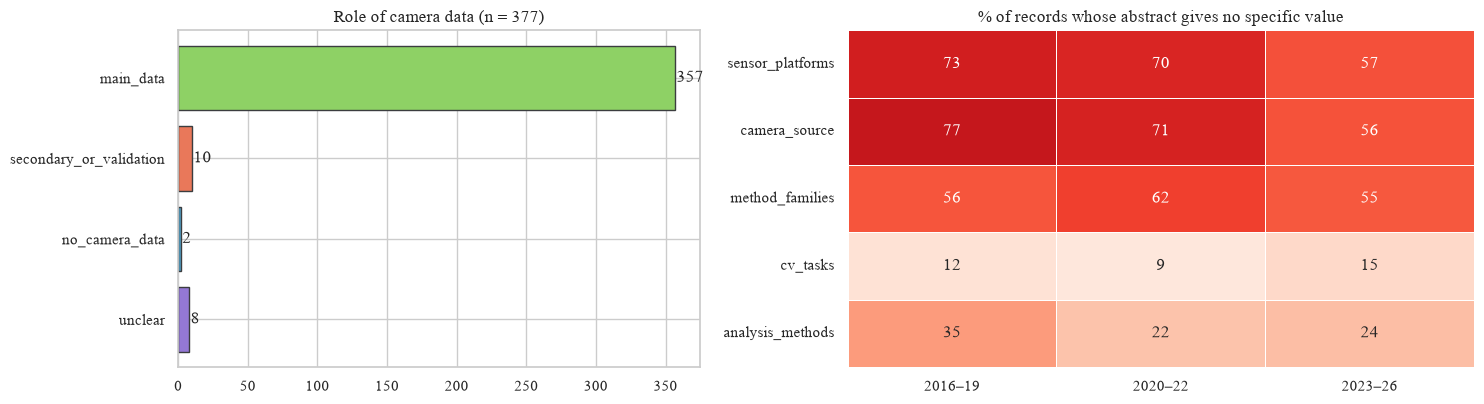

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
role = ext["camera_data_role"].value_counts().reindex(ENUMS["camera_data_role"], fill_value=0)
axes[0].barh(role.index[::-1], role.values[::-1], color=[GREEN, RED, BLUE, PURPLE][::-1], edgecolor=NAVY)
for i, v in enumerate(role.values[::-1]):
    axes[0].text(v + 1, i, str(v), va="center")
axes[0].set_title(f"Role of camera data (n = {len(ext)})", fontsize=12)

GAP = {"sensor_platforms": {"not_reported", "camera_unspecified"}, "camera_source": {"not_reported"},
       "method_families": {"not_reported", "cv_unspecified"}, "cv_tasks": {"not_reported"},
       "analysis_methods": {"not_reported"}}
gap = pd.DataFrame({p: {f: ext_a[ext_a["period"] == p][f].apply(
    lambda v: (set(v) <= g) if isinstance(v, list) else v in g).mean() * 100 for f, g in GAP.items()}
    for p in PERIODS})
sns.heatmap(gap, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, ax=axes[1], cbar=False, linewidths=0.5)
axes[1].set_title("% of records whose abstract gives no specific value", fontsize=12)
plt.tight_layout(); plt.show()

### SQ1 · Methods

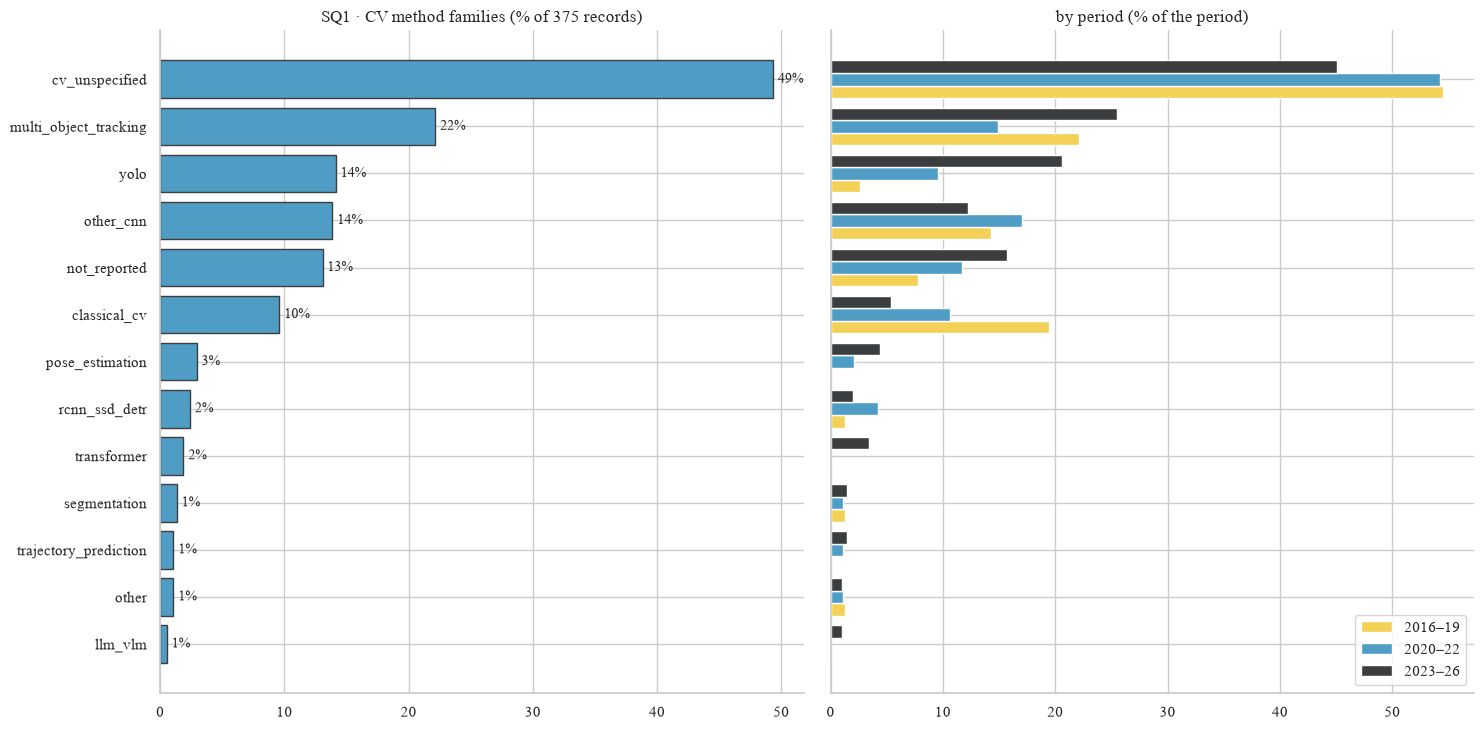

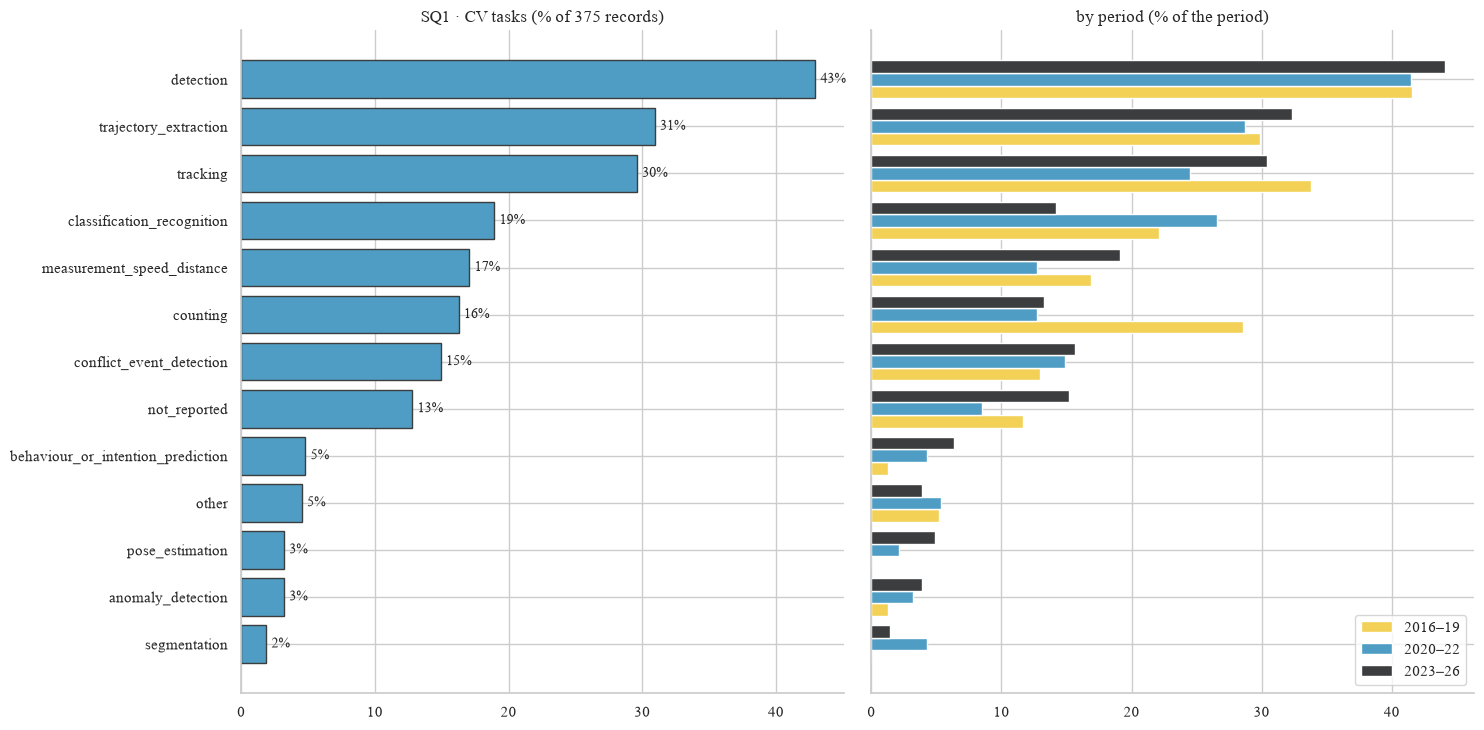

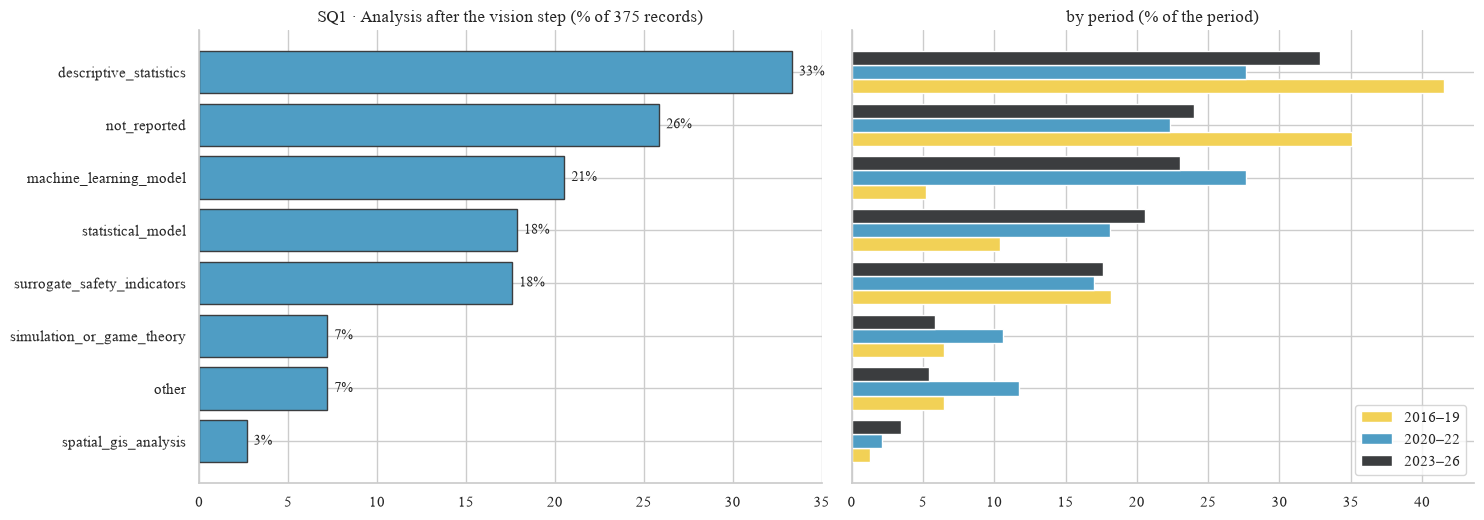

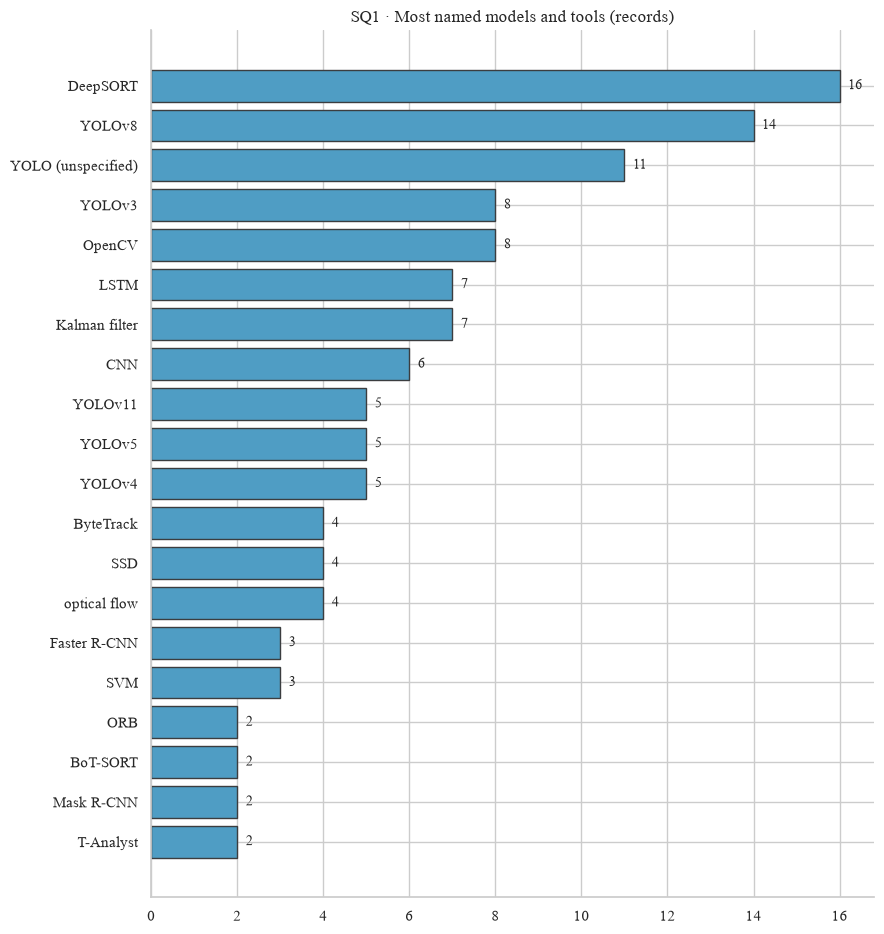

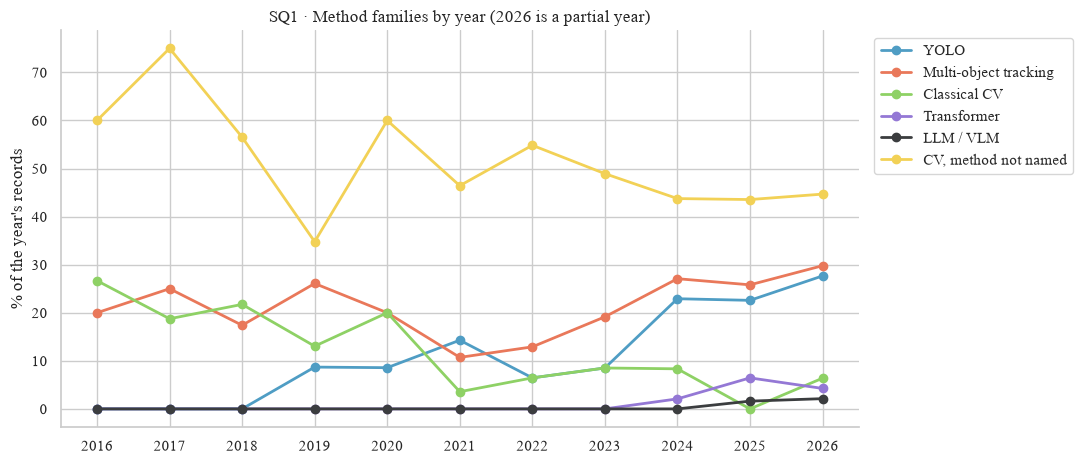

In [38]:
barh_by_period("method_families", "SQ1 · CV method families")
barh_by_period("cv_tasks", "SQ1 · CV tasks")
barh_by_period("analysis_methods", "SQ1 · Analysis after the vision step")

variants = pd.Series([v for vs in ext_a["method_variants"] for v in vs]).value_counts().head(20)[::-1]
plt.figure(figsize=(9, 0.4 * len(variants) + 1.5))
plt.barh(variants.index, variants.values, color=BLUE, edgecolor=NAVY)
for i, v in enumerate(variants.values):
    plt.text(v + 0.2, i, str(v), va="center", fontsize=10)
plt.title("SQ1 · Most named models and tools (records)", fontsize=12)
plt.gca().spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

trend([("YOLO", "method_families", "yolo"), ("Multi-object tracking", "method_families", "multi_object_tracking"),
       ("Classical CV", "method_families", "classical_cv"), ("Transformer", "method_families", "transformer"),
       ("LLM / VLM", "method_families", "llm_vlm"), ("CV, method not named", "method_families", "cv_unspecified")],
      "SQ1 · Method families by year (2026 is a partial year)")

### SQ2 · Sensors and deployment

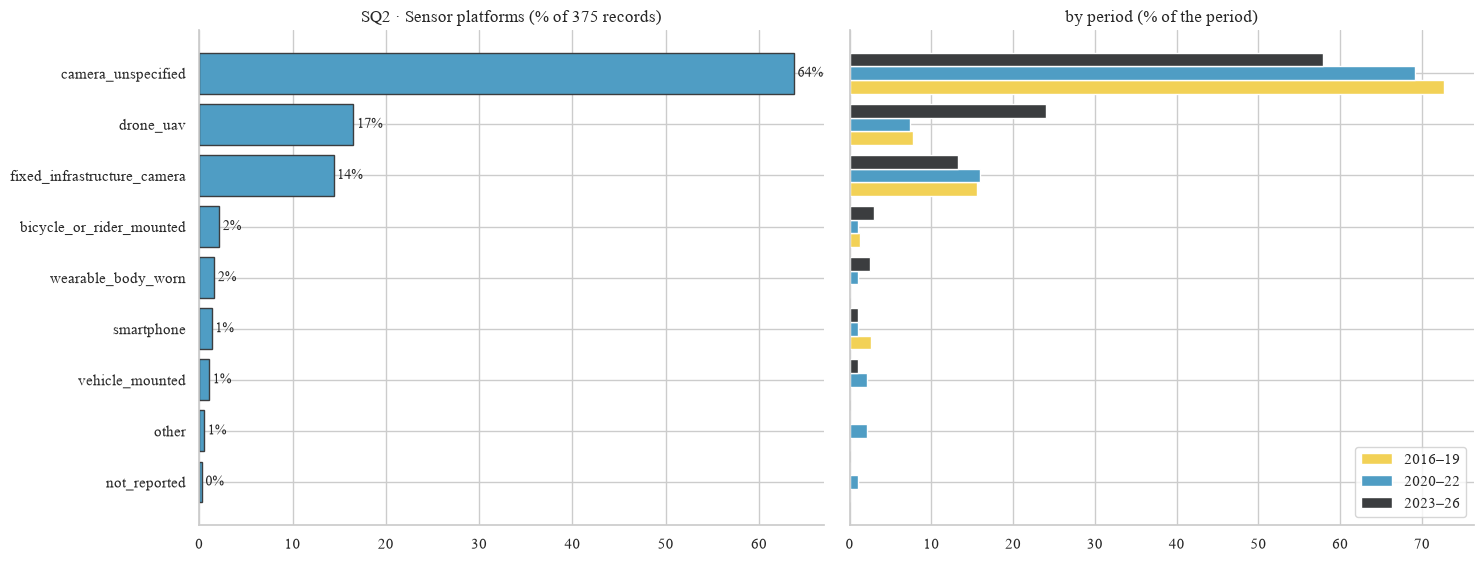

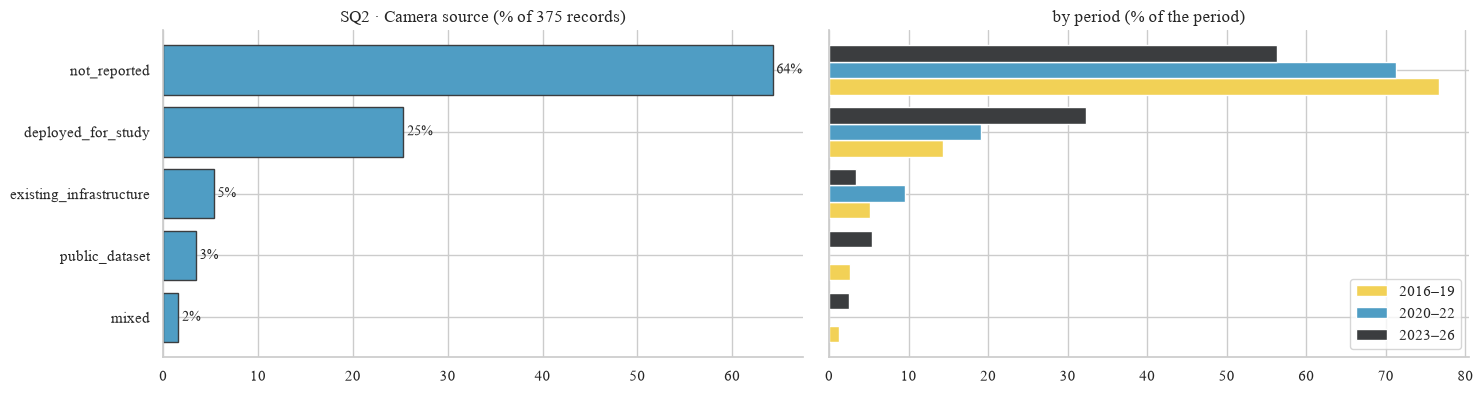

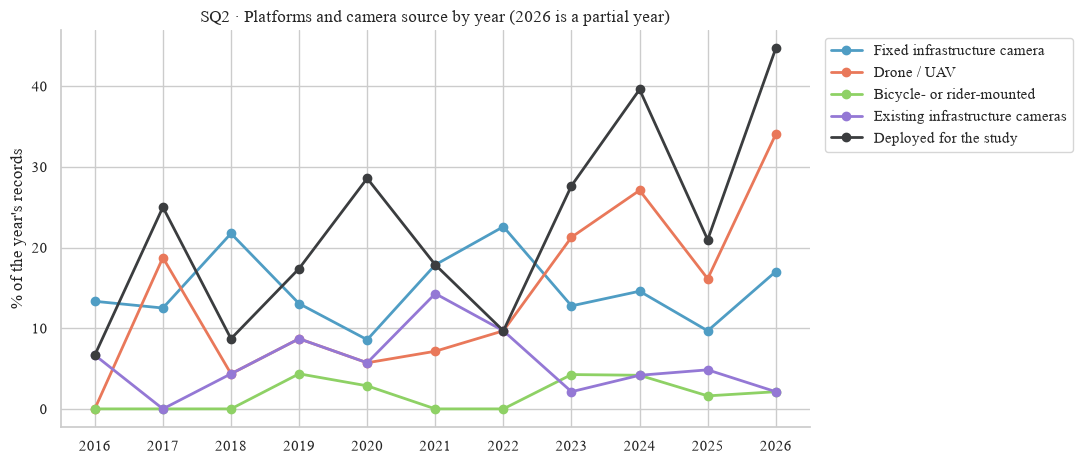

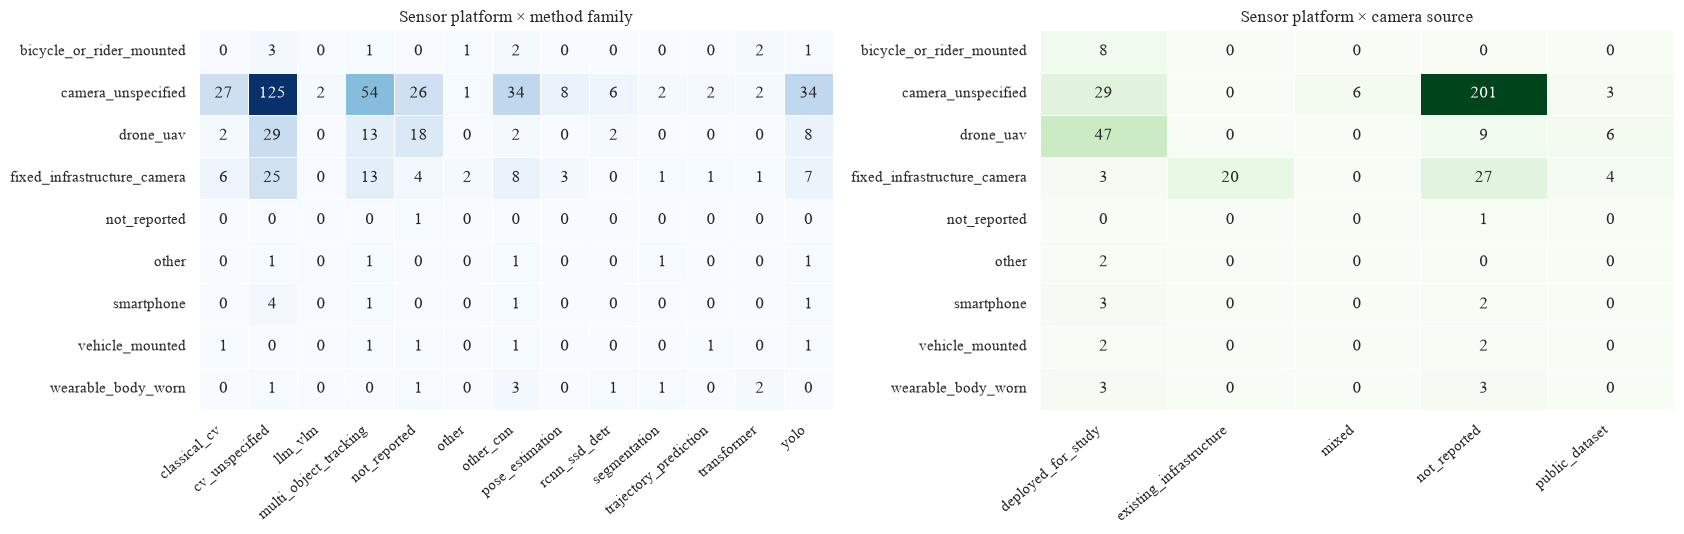

In [39]:
barh_by_period("sensor_platforms", "SQ2 · Sensor platforms")
barh_by_period("camera_source", "SQ2 · Camera source")
trend([("Fixed infrastructure camera", "sensor_platforms", "fixed_infrastructure_camera"),
       ("Drone / UAV", "sensor_platforms", "drone_uav"),
       ("Bicycle- or rider-mounted", "sensor_platforms", "bicycle_or_rider_mounted"),
       ("Existing infrastructure cameras", "camera_source", "existing_infrastructure"),
       ("Deployed for the study", "camera_source", "deployed_for_study")],
      "SQ2 · Platforms and camera source by year (2026 is a partial year)")

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
cross("sensor_platforms", "method_families", "Sensor platform × method family", axes[0])
cross("sensor_platforms", "camera_source", "Sensor platform × camera source", axes[1], "Greens")
plt.tight_layout(); plt.show()

### Road users, tasks and privacy

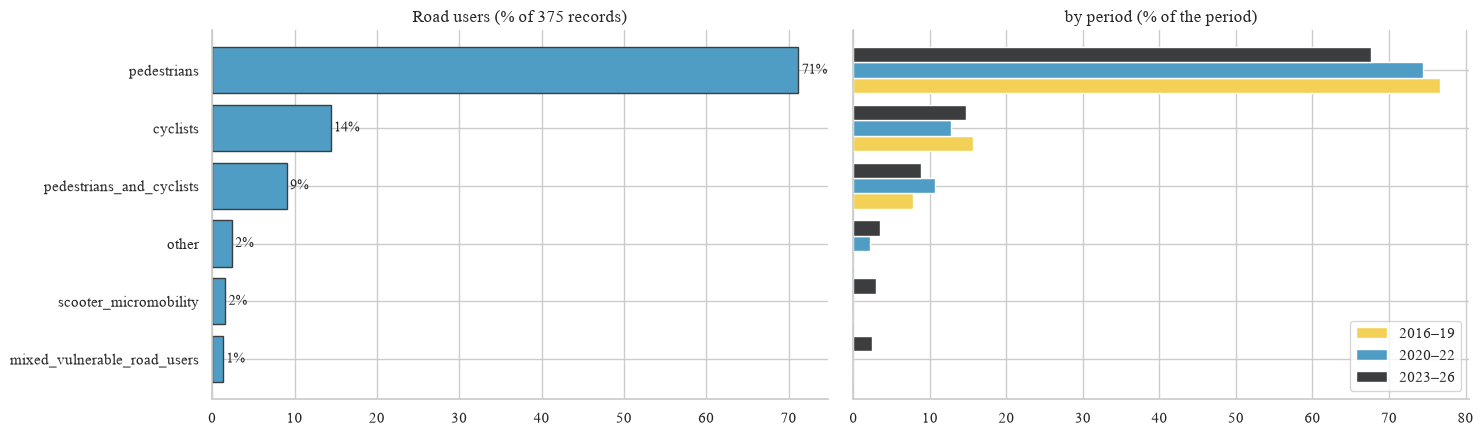

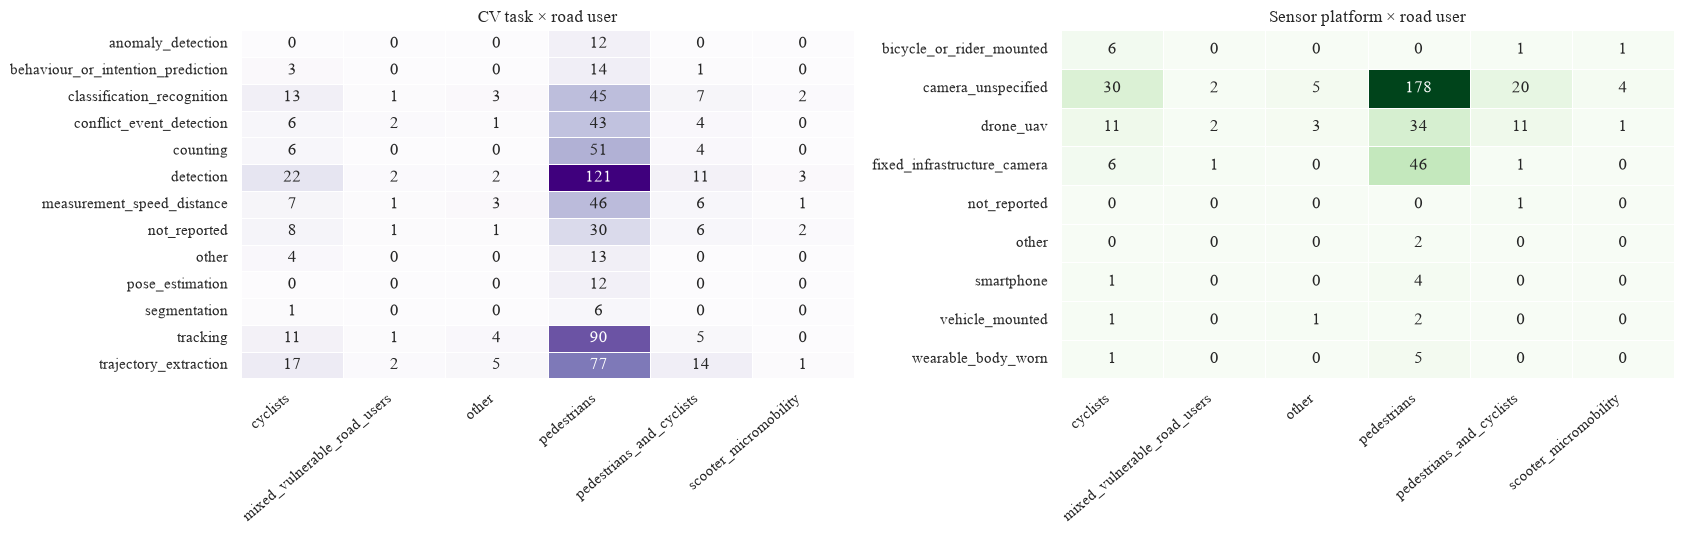

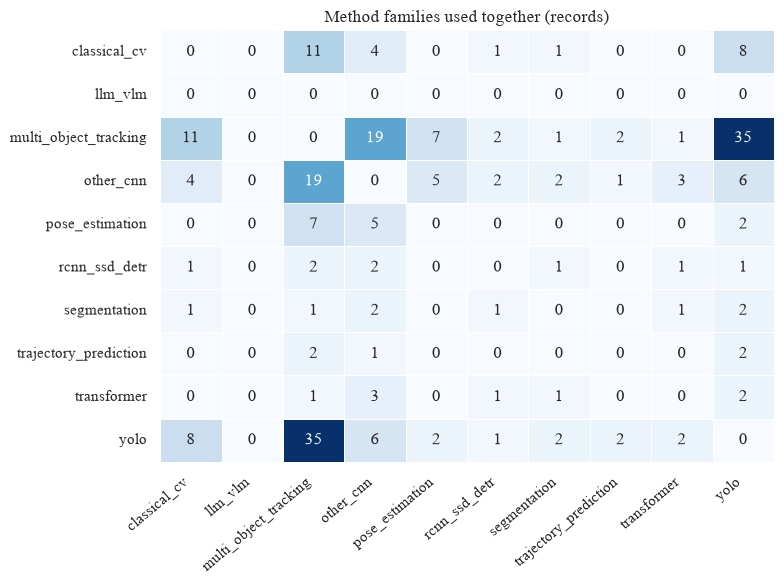

SQ4 · privacy in the abstract: {'not_mentioned': 369, 'mentioned_only': 3, 'addressed': 3}


,privacy,year,title
3,addressed,2026,Seismometer-Based Pedestrian Monitoring Using Spectral Feature Extraction and Deep Learning: A Privacy-Preserving Ap...
15,addressed,2026,Deep learning-driven digital twin system for pedestrian tracking and evacuation load assessment in public spaces
88,addressed,2025,Video-to-Text Pedestrian Monitoring (VTPM): Leveraging Large Language Models for Privacy-Preserve Pedestrian Activit...
2,mentioned_only,2026,EagleSight: A cloud-edge-device collaborative pedestrian trajectory prediction system for traffic safety
50,mentioned_only,2025,Assessment of cyclists yielding to pedestrians at an unsignalized zebra crossing in Germany using drone video
374,mentioned_only,2016,Development of The Method for Estimating Traffic Volume of Pedestrians in An Underground Mall by Use of Watch Cameras


In [40]:
barh_by_period("road_users", "Road users")

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
cross("cv_tasks", "road_users", "CV task × road user", axes[0], "Purples")
cross("sensor_platforms", "road_users", "Sensor platform × road user", axes[1], "Greens")
plt.tight_layout(); plt.show()

mf = ext_a[["record_key", "method_families"]].explode("method_families").dropna().reset_index(drop=True)
mf = mf[~mf["method_families"].isin(["not_reported", "cv_unspecified", "other"])]
B = pd.crosstab(mf["record_key"], mf["method_families"])
arr = B.T.to_numpy() @ B.to_numpy()
np.fill_diagonal(arr, 0)
co = pd.DataFrame(arr, index=B.columns, columns=B.columns)
plt.figure(figsize=(8, 6))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
plt.title("Method families used together (records)", fontsize=12); plt.xlabel(""); plt.ylabel("")
plt.setp(plt.gca().get_xticklabels(), rotation=40, ha="right"); plt.tight_layout(); plt.show()

pv = ext_a["privacy"].value_counts()
print("SQ4 · privacy in the abstract:", pv.to_dict())
ext_a[ext_a["privacy"] != "not_mentioned"][["privacy", "year", "title"]].sort_values("privacy")

## SQ3 · Pass 2: LLM-proposed codebook

One call reads every one-sentence summary and proposes 8–12 categories. Review the table; to change it, paste an edited dict in `CODEBOOK_OVERRIDE` (label → definition) and re-run the next cell.

In [ ]:
summaries = ext_a["observed_summary"].fillna("").tolist()
PROPOSE_PROMPT = ("You will read one-sentence summaries of what each study observes or measures about pedestrians, "
                  "cyclists or scooter users and their environment. Propose a codebook of 8 to 12 categories of "
                  "WHAT IS OBSERVED OR ASSESSED (not methods or sensors) that together cover most studies; a study "
                  "can fall in more than one. For each: a short snake_case label, a one-line definition, and the "
                  "numbers of 3 example summaries.")
PROPOSE_SCHEMA = {"type": "object", "additionalProperties": False,
                  "properties": {"categories": {"type": "array", "items": {
                      "type": "object", "additionalProperties": False,
                      "properties": {"label": {"type": "string"}, "definition": {"type": "string"},
                                     "examples": {"type": "array", "items": {"type": "integer"}}},
                      "required": ["label", "definition", "examples"]}}},
                  "required": ["categories"]}
listing = "\n".join(f"{i}. {s}" for i, s in enumerate(summaries))
p_hash = hashlib.sha1((PROPOSE_PROMPT + listing).encode()).hexdigest()[:10]
p_path = os.path.join(CONFIG["CACHE_DIR"], f"07_sq3_codebook_{m['name']}__{p_hash}.json")
if os.path.exists(p_path):
    proposed = json.load(open(p_path, encoding="utf-8"))
else:
    raw, _, _ = call_model(PROPOSE_PROMPT, listing, PROPOSE_SCHEMA, "codebook")
    proposed = parse_json(raw)["categories"]
    json.dump(proposed, open(p_path, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
for c in proposed:
    print(f"\n{c['label']}: {c['definition']}")
    for i in c["examples"][:3]:
        if 0 <= i < len(summaries):
            print(f"   • {summaries[i]}")


locomotion_kinematics: Measures individual movement such as speed, acceleration, gait, and motion trajectories. Examples: #0, #1, #119.
   • Pedestrian walking speeds, behavioral variability, and demographic shifts were examined across time slots, temperatures, and emergency periods.
   • Bicyclists’ speed, acceleration, deceleration, acceptable risk, and acceptable distance were compared across obstacle scenarios.
   • Pedestrian walking speeds were estimated and compared between one-stage and two-stage street crossings.

traffic_flow_crowding: Assesses road-user counts, volumes, flow, density, queues, or waiting in pedestrian and micromobility spaces. Examples: #5, #54, #259.
   • Pedestrian flow, waiting behavior, crossing activity, and localized density are measured at an urban crosswalk.
   • Pedestrian flow rate, density, velocity, and velocity-based behaviors on footbridges are measured for crowd and structural monitoring.
   • Pedestrian crowd densities and counts were measure

## SQ3 · Pass 3: reclassify

In [ ]:
CODEBOOK_OVERRIDE = None      # e.g. {"crossing_conflicts": "pedestrian-vehicle conflicts at crossings", ...}
CODEBOOK = CODEBOOK_OVERRIDE or {c["label"]: c["definition"] for c in proposed}

cb_schema = {"type": "object", "additionalProperties": False,
             "properties": {"categories": {"type": "array",
                                           "items": {"type": "string", "enum": list(CODEBOOK) + ["other"]}}},
             "required": ["categories"]}
cb_prompt = ("Assign the study to one or more categories of what is observed or assessed, using only the title "
             "and abstract.\n" + "\n".join(f"- {k}: {v}" for k, v in CODEBOOK.items()) + "\n- other: none of the above")
cb_hash = hashlib.sha1((cb_prompt + json.dumps(cb_schema)).encode()).hexdigest()[:10]
cb_path = os.path.join(CONFIG["CACHE_DIR"], f"07_sq3_{m['name']}__{cb_hash}.jsonl")
cb = {}
if os.path.exists(cb_path):
    cb = {json.loads(l)["record_key"]: json.loads(l)["categories"] for l in open(cb_path, encoding="utf-8")}
lookup = df.set_index("record_key")
todo = ext_a[~ext_a["record_key"].isin(cb)]
print(f"{len(cb)} cached, {len(todo)} to classify")
with open(cb_path, "a", encoding="utf-8") as fh:
    for _, r in tqdm(todo.iterrows(), total=len(todo)):
        user = f"Title: {r['title']}\n\nAbstract: {lookup.loc[r['record_key'], 'abstract_clean']}"
        raw, _, _ = call_model(cb_prompt, user, cb_schema, "sq3")
        cats = [c if c in CODEBOOK else "other" for c in parse_json(raw).get("categories", [])] or ["other"]
        cb[r["record_key"]] = sorted(set(cats))
        fh.write(json.dumps({"record_key": r["record_key"], "categories": cb[r["record_key"]]}) + "\n")
ext["sq3_categories"] = ext["record_key"].map(cb)
ext_a = analysis_set()
print(f"'other' share: {ext_a['sq3_categories'].apply(lambda v: 'other' in v).mean():.0%}")

375 cached, 0 to classify


0it [00:00, ?it/s]

'other' share: 1%


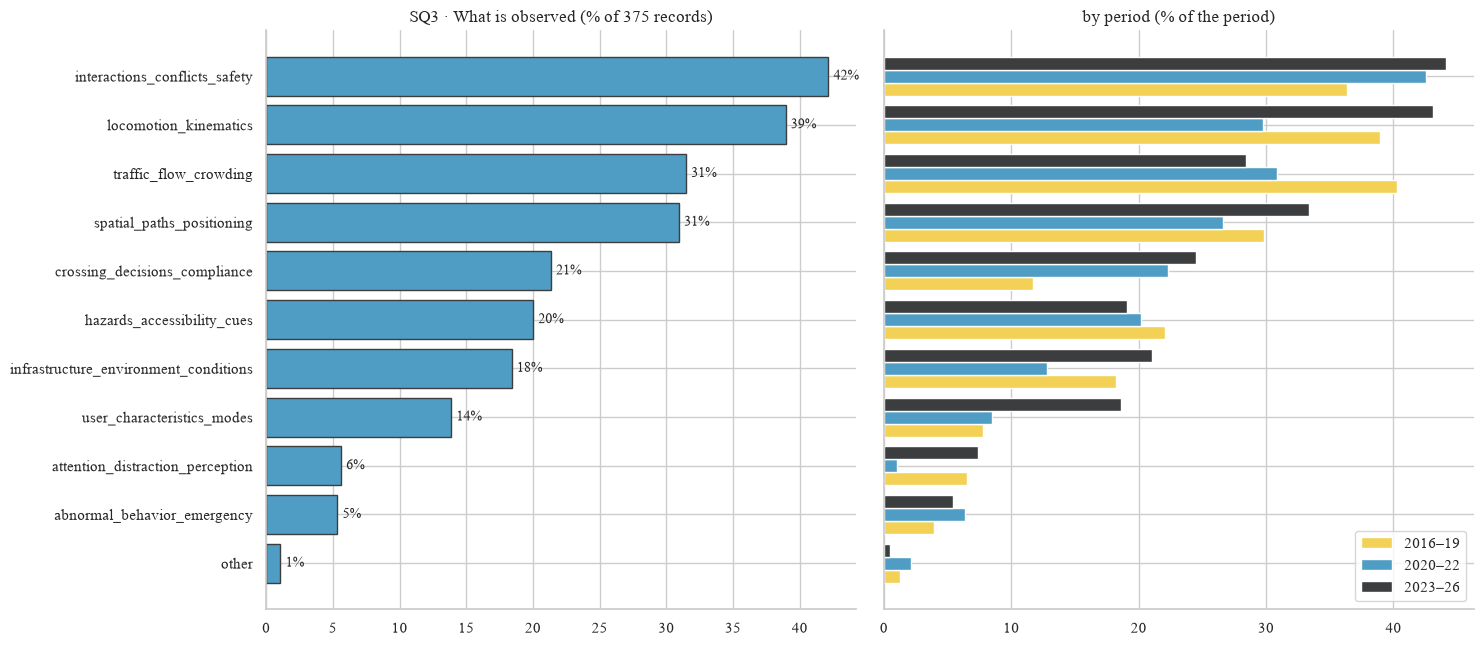

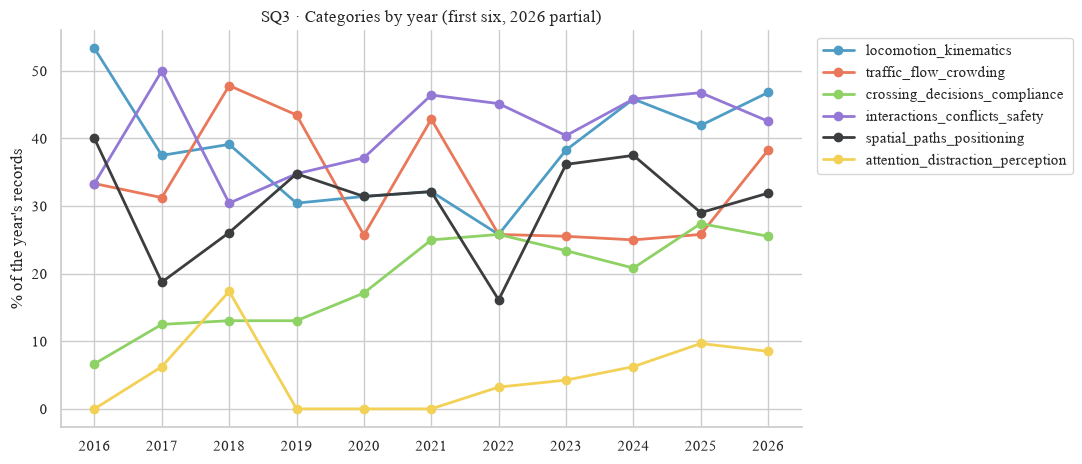

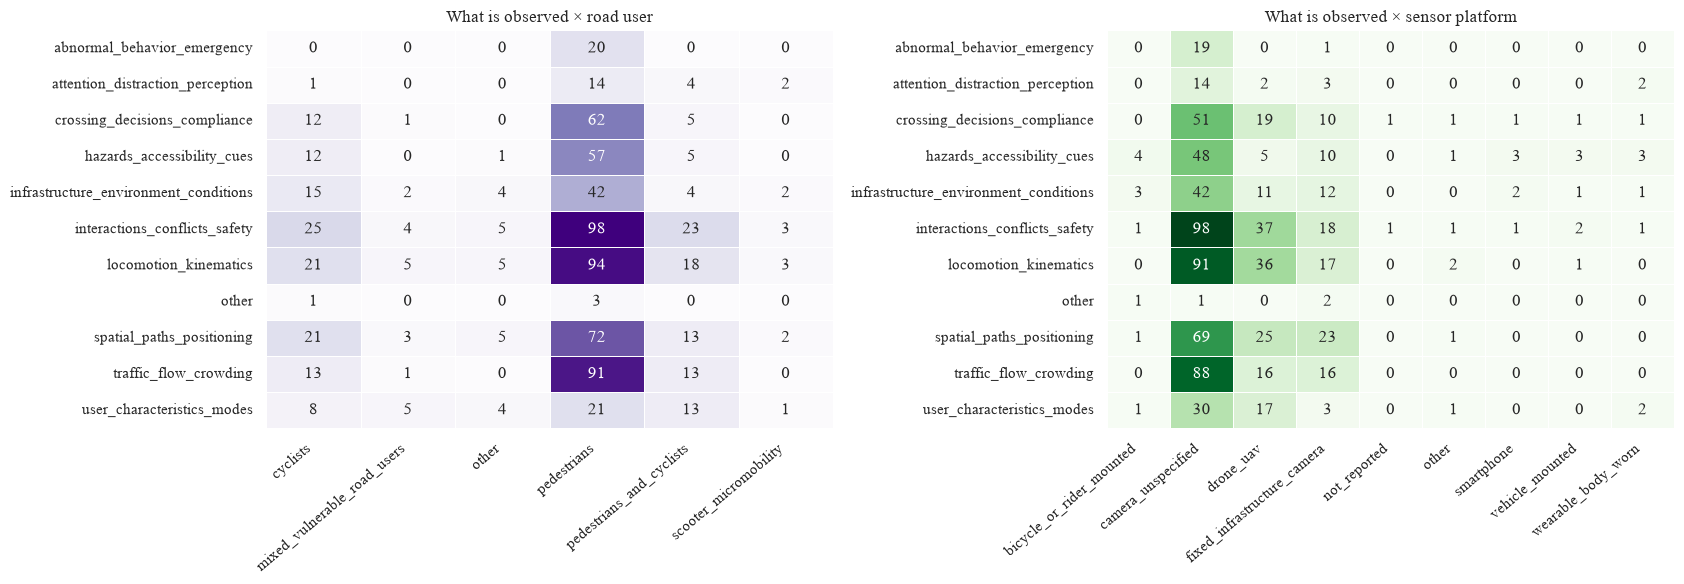

In [43]:
barh_by_period("sq3_categories", "SQ3 · What is observed")
trend([(c, "sq3_categories", c) for c in list(CODEBOOK)[:6]], "SQ3 · Categories by year (first six, 2026 partial)")
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
cross("sq3_categories", "road_users", "What is observed × road user", axes[0], "Purples")
cross("sq3_categories", "sensor_platforms", "What is observed × sensor platform", axes[1], "Greens")
plt.tight_layout(); plt.show()

## Save

In [44]:
ext.to_json(CONFIG["OUTPUT_PATH"], orient="records", indent=2, force_ascii=False)
print("Saved", CONFIG["OUTPUT_PATH"], f"({len(ext)} records)")

Saved ../data/09_rq_extraction.json (377 records)
